In [ ]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Busco el csv automáticamente en esta carpeta y subcarpetas
archivos = glob.glob("car_crashes.csv", recursive=True)
print(archivos)

df = pd.read_csv(archivos[0])
df.head()

['car_crashes.csv']


,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses,abbrev
0,18.8,7.332,5.640,18.048,15.040,784.55,145.08,AL
1,18.1,7.421,4.525,16.290,17.014,1053.48,133.93,AK
2,18.6,6.510,5.208,15.624,17.856,899.47,110.35,AZ
3,22.4,4.032,5.824,21.056,21.280,827.34,142.39,AR
4,12.0,4.200,3.360,10.920,10.680,878.41,165.63,CA


In [5]:
# Me quedo solo con las columnas numéricas (abbrev es texto y se descarta)
num = df.select_dtypes(include=np.number).copy()
print(num.isnull().sum())   # reviso cuántos nulos hay

# Nulos: los relleno con la mediana
num = num.fillna(num.median())

# Outliers: recorto los valores extremos con el método IQR
for c in num.columns:
    q1, q3 = num[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    num[c] = num[c].clip(q1 - 1.5 * iqr, q3 + 1.5 * iqr)

# Quito columnas constantes porque no se pueden correlacionar
num = num.loc[:, num.std() > 0]
num.describe()

total             0
speeding          0
alcohol           0
not_distracted    0
no_previous       0
ins_premium       0
ins_losses        0
dtype: int64


,total,speeding,alcohol,not_distracted,no_previous,ins_premium,ins_losses
count,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000,51.000000
mean,15.790196,4.998196,4.793725,13.577588,14.004882,886.957647,134.493137
std,4.122002,2.017747,1.484544,4.497282,3.764672,178.296285,24.835922
min,5.900000,1.792000,1.593000,1.985000,5.900000,641.960000,82.750000
25%,12.750000,3.766500,3.894000,10.478000,11.348000,768.430000,114.645000
50%,15.600000,4.608000,4.554000,13.857000,13.775000,858.970000,136.050000
75%,18.500000,6.439000,5.604000,16.140000,16.755000,1007.945000,151.870000
max,23.900000,9.450000,8.169000,23.661000,21.280000,1301.520000,194.780000


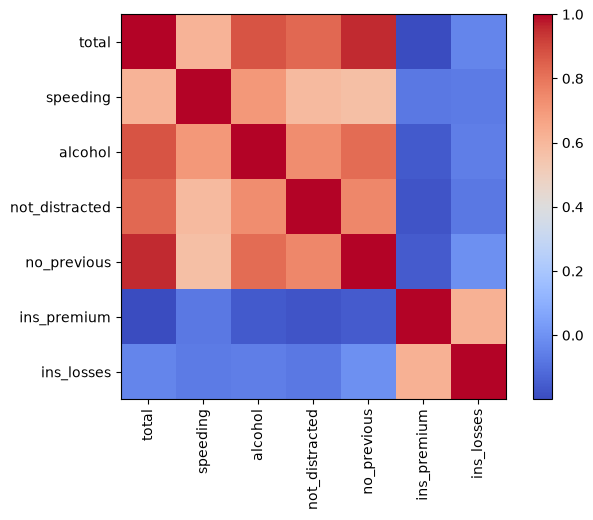

no_previous  total             0.956179
total        alcohol           0.877480
             not_distracted    0.830152
dtype: float64


In [11]:
# Matriz de correlación
corr = num.corr()

# Heatmap sencillo para ver qué variables se relacionan más
plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm")
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.show()

# Los 3 pares con mayor correlación absoluta
pares = corr.abs().unstack().sort_values(ascending=False)
pares = pares[pares < 0.9999].iloc[::2].head(3)
print(pares)

# Elegí estos 3 pares para el análisis
pares_elegidos = [("no_previous", "total"), ("alcohol", "total"), ("not_distracted", "total")]

In [7]:
# Modelo 1: cuadrático  y = a*x² + b*x + c
def cuadratico(x, a, b, c):
    return a * x**2 + b * x + c

# Modelo 2: exponencial  y = a*exp(b*x) + c
def exponencial(x, a, b, c):
    return a * np.exp(b * x) + c

# R² calculado a mano: 1 - (error del modelo / variación total)
def r2(y, pred):
    return 1 - np.sum((y - pred)**2) / np.sum((y - y.mean())**2)

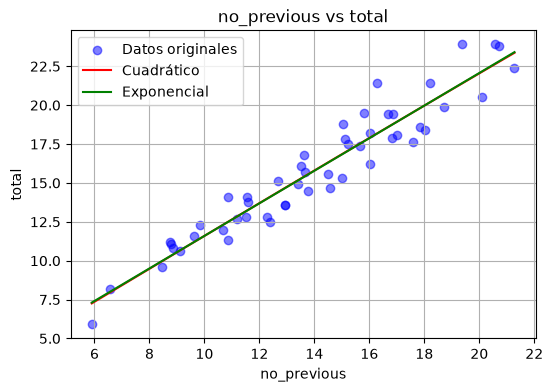

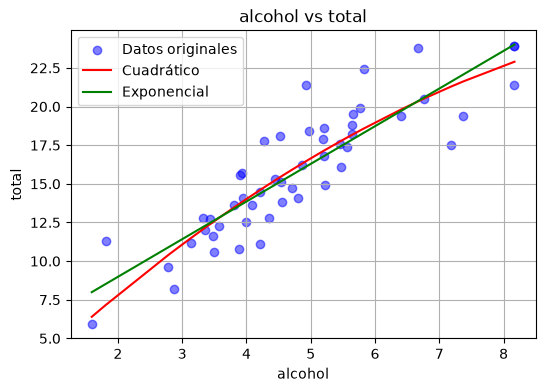

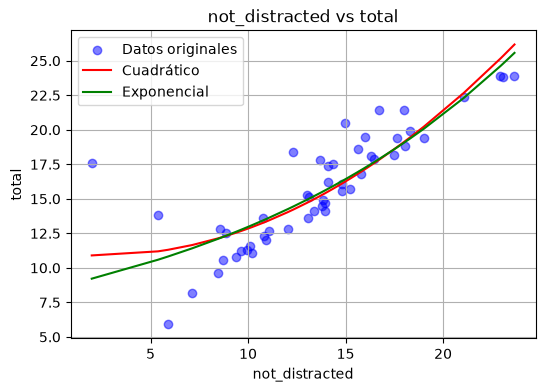

,Variables,Modelo,R²,R
0,no_previous vs total,Cuadrático,0.9143,0.9562
1,no_previous vs total,Exponencial,0.9143,0.9562
2,alcohol vs total,Cuadrático,0.7836,0.8852
3,alcohol vs total,Exponencial,0.7700,0.8775
4,not_distracted vs total,Cuadrático,0.7478,0.8647
5,not_distracted vs total,Exponencial,0.7288,0.8537


In [12]:
resultados = []

for (xc, yc) in pares_elegidos:
    x = num[xc].values
    y = num[yc].values

    # Escalo x entre 0 y 1 para que la exponencial no se desborde
    x_s = (x - x.min()) / (x.max() - x.min())

    # Ajusto el modelo cuadrático
    try:
        p1, _ = curve_fit(cuadratico, x_s, y, maxfev=5000)
        y1 = cuadratico(x_s, *p1)
    except RuntimeError:
        y1 = np.full_like(y, y.mean(), dtype=float)   # si no converge, uso la media

    # Ajusto el modelo exponencial
    try:
        p2, _ = curve_fit(exponencial, x_s, y, p0=[1, 1, y.min()], maxfev=5000)
        y2 = exponencial(x_s, *p2)
    except RuntimeError:
        y2 = np.full_like(y, y.mean(), dtype=float)

    # Guardo R² y R de cada modelo
    for nombre, pred in [("Cuadrático", y1), ("Exponencial", y2)]:
        v = r2(y, pred)
        r = np.sqrt(v) if v >= 0 else np.nan   # si R² es negativo, R no se puede calcular
        resultados.append([f"{xc} vs {yc}", nombre, round(v, 4), round(r, 4)])

    # Gráfica comparando datos reales y predicciones
    orden = np.argsort(x)
    plt.figure(figsize=(6, 4))
    plt.scatter(x, y, color="blue", alpha=0.5, label="Datos originales")
    plt.plot(x[orden], y1[orden], color="red", label="Cuadrático")
    plt.plot(x[orden], y2[orden], color="green", label="Exponencial")
    plt.title(f"{xc} vs {yc}")
    plt.xlabel(xc); plt.ylabel(yc)
    plt.legend(); plt.grid(True)
    plt.show()

# Tabla final con todos los coeficientes
tabla = pd.DataFrame(resultados, columns=["Variables", "Modelo", "R²", "R"])
tabla.to_csv("tabla_coeficientes.csv", index=False)
tabla